In [31]:
%pip install matplotlib numpy scipy pillow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [43]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from scipy.ndimage import zoom
import scipy.signal as sp
import scipy.fft as fft
from PIL import Image, ImageFilter

In [ ]:
def Decimate(img, factor, method):
    """
    Decimate an image by a given factor using a specified method.

    Parameters:
    img (numpy.ndarray): Input image to be decimated.
    factor (int): Factor by which to decimate the image.
    method (str): Method to use for decimation ('nearest', 'bilinear', 'bicubic').

    Returns:
    numpy.ndarray: Decimated image.
    """

    if method == 'nearest':
        return img[::factor, ::factor]
    elif method == 'bilinear':
        return zoom(img, (1/factor, 1/factor), order=1)
    elif method == 'bicubic':
        return zoom(img, (1/factor, 1/factor), order=3)
    else:
        raise ValueError("Method must be 'nearest', 'bilinear', or 'bicubic'.")

In [66]:
def ShowImage(img, title='Image', cmap="gray", vmin=0, vmax=255):
    """
    Display an image using matplotlib.

    Parameters:
    img (numpy.ndarray): Image to be displayed.
    title (str): Title of the image display window.
    """
    plt.figure()
    plt.imshow(img, cmap=cmap, vmin=vmin, vmax=vmax)
    plt.title(title)
    plt.axis('off')
    plt.show()

## Ejercicio 1

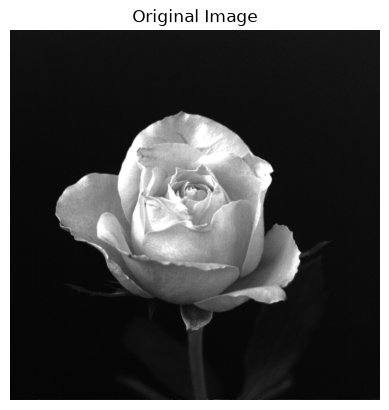

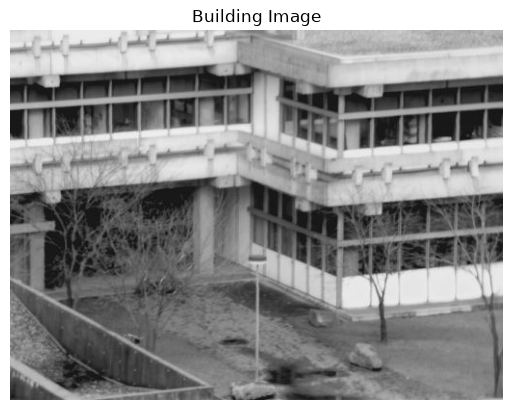

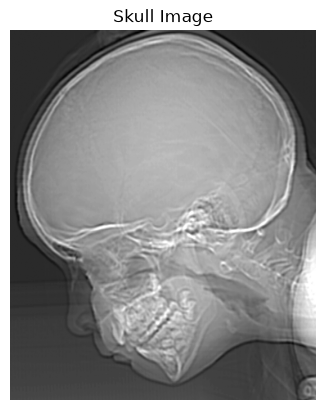

In [22]:
rose = mpimg.imread('ej1-rose.tif')
building = mpimg.imread('ej1-building.jpg')
skull = mpimg.imread('ej1-skull.tif')

ShowImage(rose, 'Original Image')
ShowImage(building, 'Building Image')
ShowImage(skull, 'Skull Image')

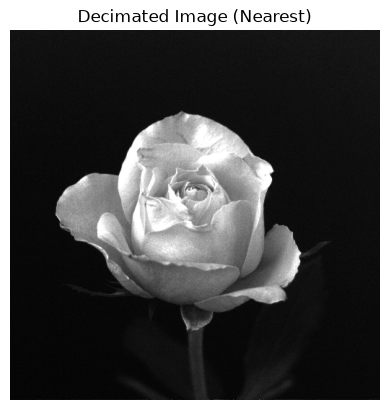

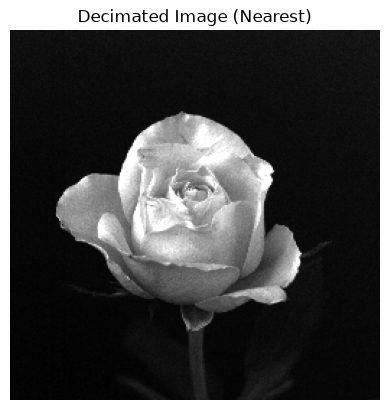

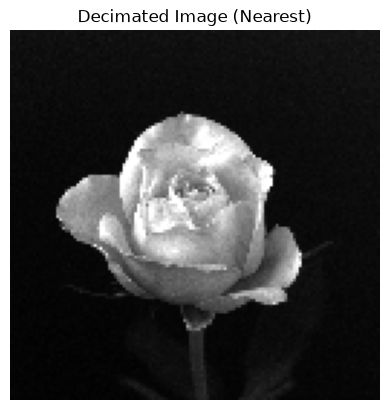

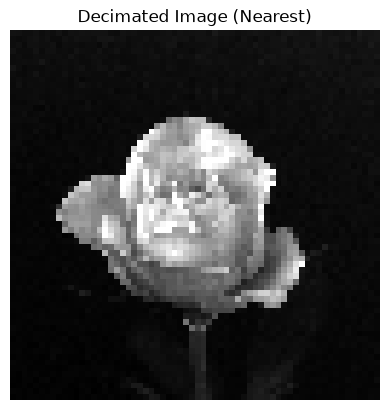

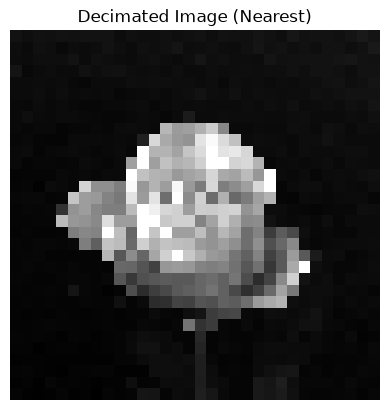

In [23]:
rose1 = Decimate(rose, 2, 'nearest')
ShowImage(rose1, 'Decimated Image (Nearest)')

rose2 = Decimate(rose1, 2, 'nearest')
ShowImage(rose2, 'Decimated Image (Nearest)')

rose3 = Decimate(rose2, 2, 'nearest')
ShowImage(rose3, 'Decimated Image (Nearest)')

rose4 = Decimate(rose3, 2, 'nearest')
ShowImage(rose4, 'Decimated Image (Nearest)')

rose5 = Decimate(rose4, 2, 'nearest')
ShowImage(rose5, 'Decimated Image (Nearest)')

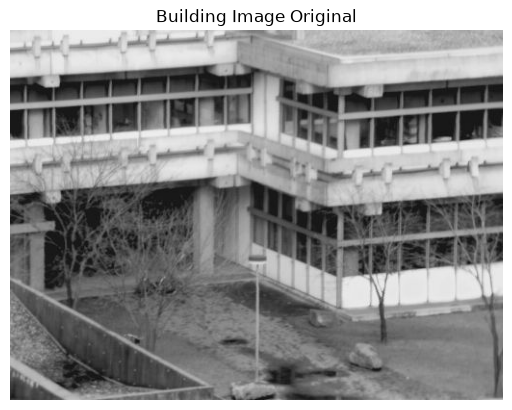

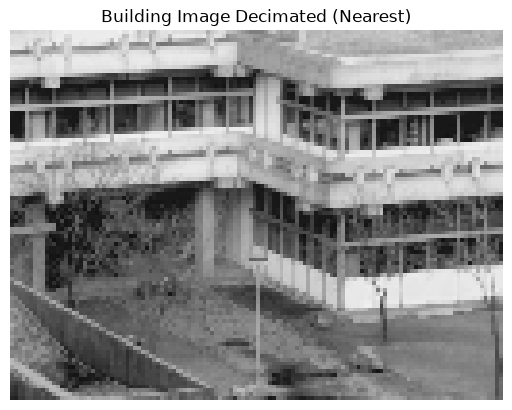

In [24]:
ShowImage(building, 'Building Image Original')
ShowImage(Decimate(building, 4, 'nearest'), 'Building Image Decimated (Nearest)')

In [25]:
def ReduceCuantization(img, factor):
    """
    Reduce the quantization of an image by a given factor.

    Parameters:
    img (numpy.ndarray): Input image to be quantized.
    factor (int): Factor by which to reduce the quantization.

    Returns:
    numpy.ndarray: Quantized image.
    """
    return (img // factor) * factor

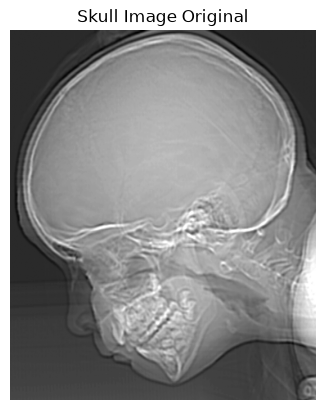

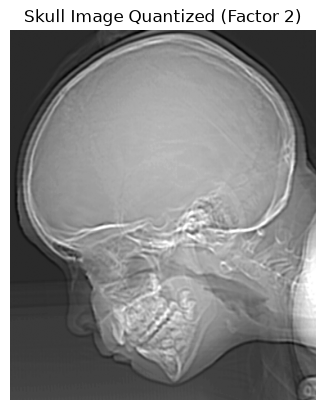

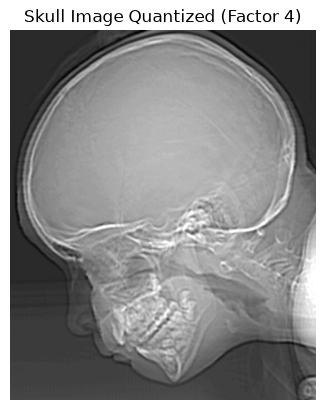

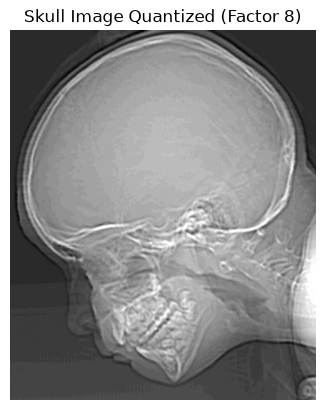

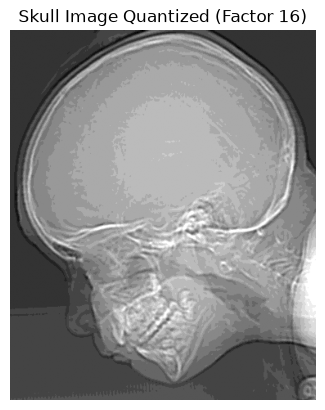

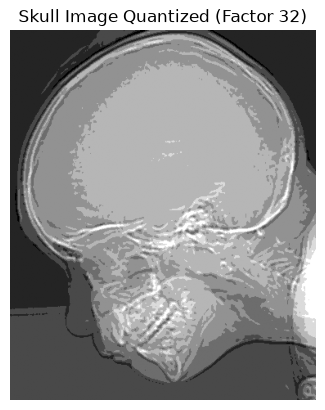

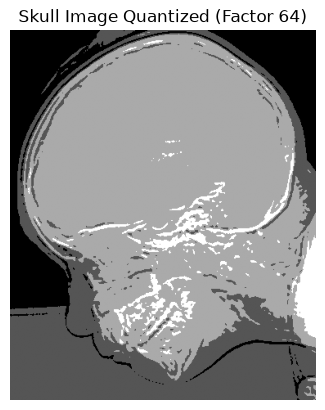

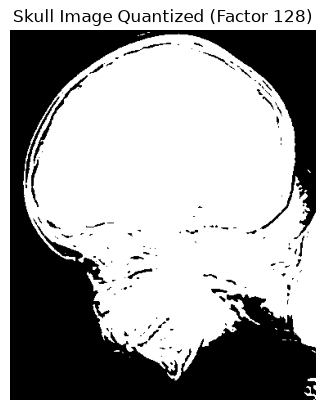

In [26]:
ShowImage(skull, 'Skull Image Original')
skull1 = ReduceCuantization(skull, 2)
ShowImage(skull1, 'Skull Image Quantized (Factor 2)')
skull2 = ReduceCuantization(skull, 4)
ShowImage(skull2, 'Skull Image Quantized (Factor 4)')
skull3 = ReduceCuantization(skull, 8)
ShowImage(skull3, 'Skull Image Quantized (Factor 8)')
skull4 = ReduceCuantization(skull, 16)
ShowImage(skull4, 'Skull Image Quantized (Factor 16)')
skull5 = ReduceCuantization(skull, 32)
ShowImage(skull5, 'Skull Image Quantized (Factor 32)')
skull6 = ReduceCuantization(skull, 64)
ShowImage(skull6, 'Skull Image Quantized (Factor 64)')
skull7 = ReduceCuantization(skull, 128)
ShowImage(skull7, 'Skull Image Quantized (Factor 128)')

## Ejercicio 2

In [41]:
def ApplyFilter(img, filter):
    return sp.convolve2d(img, filter, mode='same')

2


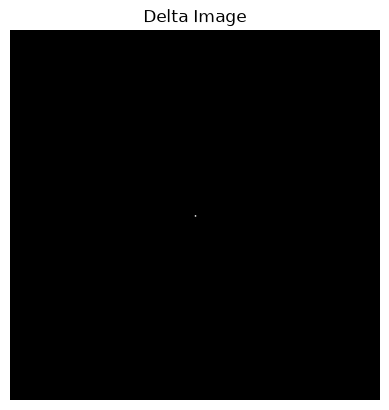

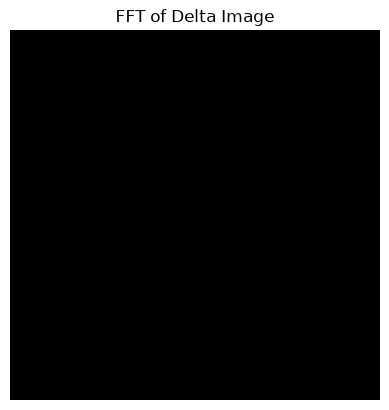

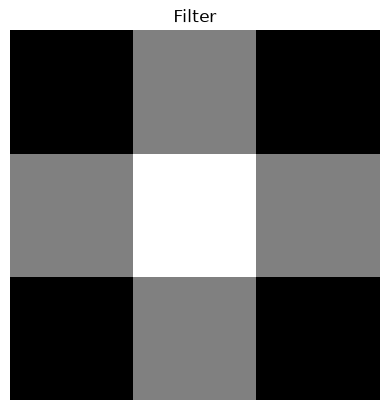

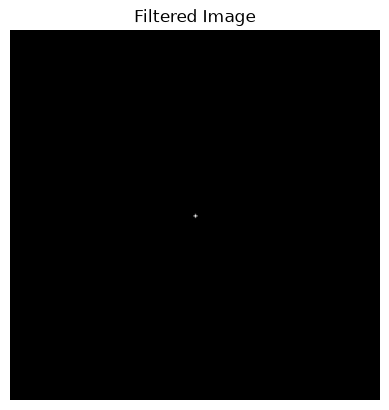

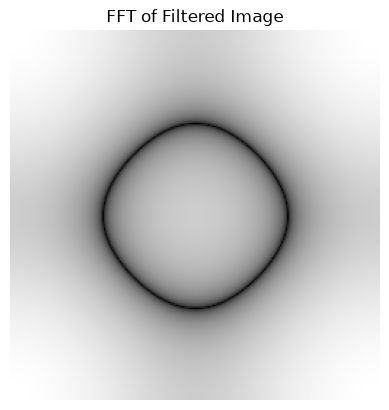

In [ ]:
N = 256
img = np.zeros((N, N))
img[N//2, N//2] = 256  # Delta at 0, 0
ShowImage(img, 'Delta Image')

ShowImage(20*np.log10(np.abs(fft.fft2(img))), 'FFT of Delta Image')

# Filter
filter = np.array([[0, 1/6, 0], [1/6, 1/3, 1/6], [0, 1/6, 0]])
ShowImage(filter, 'Filter')

filtered_img = ApplyFilter(img, filter)
ShowImage(filtered_img, 'Filtered Image')
ShowImage(20*np.log10(1 + np.abs(fft.fft2(filtered_img))), 'FFT of Filtered Image')

2


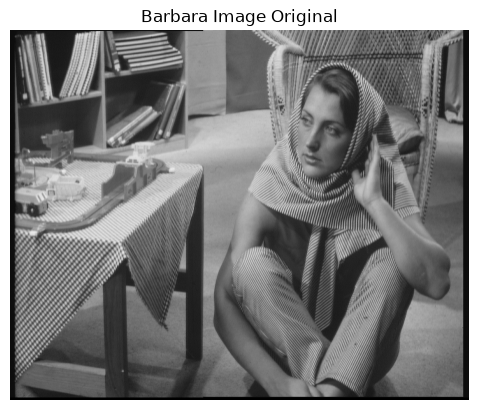

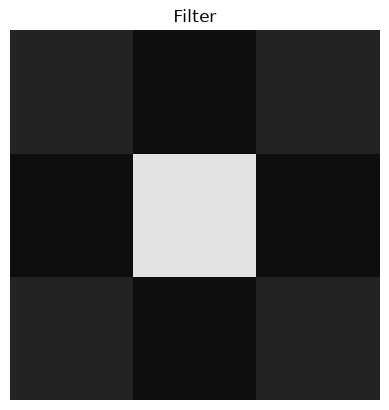

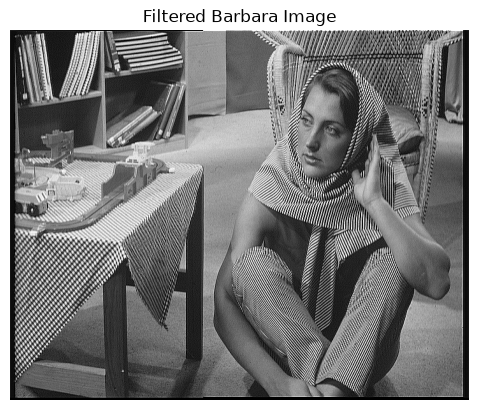

In [69]:
barbara = mpimg.imread('barbara.gif')
barbara = barbara[:, :, 0]
print(barbara.ndim)
ShowImage(barbara, 'Barbara Image Original')

filter = np.array([
    [-0.1667, -0.6667, -0.1667],
    [-0.6667,  4.3333, -0.6667],
    [-0.1667, -0.6667, -0.1667]
])

ShowImage(filter, 'Filter', vmin=-1, vmax=5)

filtered_barbara = ApplyFilter(barbara, filter)
ShowImage(filtered_barbara, 'Filtered Barbara Image')